# Mini-Project 1: UBOS District Population Forecaster
**Course:** OOP with Python, Assignment 1 (Advent 2026)

**Scenario.** A district planning unit wants 5-year population forecasts so it can plan primary-school classrooms. We have 10 years of population estimates (2015-2024, **in thousands**, illustrative) for three districts, and we add two of our own.

**How this notebook is organised** (one section per task in the brief):

| Section | What we do |
|---|---|
| 0 | Imports and data |
| 1 | `DistrictPopulation` class (validation, `__repr__`, `__len__`) |
| 2 | Descriptive statistics: `statistics` module vs NumPy, and what `ddof` means |
| 3 | Year-on-year growth and CAGR |
| 4 | Three forecasting models built on an abstract `Forecaster` |
| 5 | Validation: train on 2015-2021, test on 2022-2024 (MAE, RMSE, MAPE) |
| 6 | Forecast 2025-2029 with the best model per district |
| 7 | Plots |
| 8 | Classroom planning |
| Extension | Bootstrap 95% prediction intervals, and a critique of the Fibonacci model |

**Design rule:** always pick the simplest tool that does the job (plain NumPy, small functions, short classes).

## 0. Imports and data

In [23]:
import statistics                      # Python's built-in statistics module
from abc import ABC, abstractmethod    # tools for abstract base classes

import numpy as np                     # fast arrays and maths
import pandas as pd                    # tables (DataFrames) for readable output
import matplotlib.pyplot as plt        # plotting

pd.options.display.float_format = "{:,.2f}".format   # show numbers with 2 decimals

# Our reusable code lives in the src/ folder (run this notebook from the repository root)
from src.population import DistrictPopulation
from src.analysis import (yoy_growth, cagr, error_metrics, classrooms_needed,
                          PRIMARY_SHARE, PUPILS_PER_CLASSROOM)
from src.forecasting import (Forecaster, LinearTrendForecaster, ExponentialForecaster,
                             FibonacciRatioForecaster, fibonacci_ratios, bootstrap_interval)

In [24]:
# The 10 years we have data for
YEARS = list(range(2015, 2025))

# Population in THOUSANDS. Kampala, Wakiso and Gulu come from the brief.
# Mbarara and Jinja are my two extra districts (illustrative numbers I made up,
# with a fast-growing and a slow-growing pattern so the comparison is interesting).
RAW_DATA = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [320, 330, 345, 360, 375, 390, 410, 430, 455, 480],
    "Mbarara": [210, 218, 227, 236, 246, 256, 267, 278, 290, 302],
    "Jinja":   [440, 447, 455, 462, 470, 478, 485, 493, 501, 509],
}

## 1. The `DistrictPopulation` class

**Idea:** one object = one district. The object keeps its `name`, `years` and `populations` as NumPy arrays, and refuses to be created if the data is bad (this is called *validation*).

Two "dunder" (double-underscore) methods make our object feel like a normal Python object:
- `__len__` lets us call `len(district)`.
- `__repr__` controls how the object prints, so `print(district)` is readable instead of `<object at 0x...>`.

In [3]:
# The class is defined in src/population.py (open it to read the full code).
# Here we just print its docstring to remind ourselves what it does.
print(DistrictPopulation.__doc__)

Population history of ONE district.

Parameters
----------
name : str
    District name, e.g. "Kampala".
years : list or array of int
    The years observed, e.g. [2015, ..., 2024].
populations : list or array of numbers
    Population (in thousands) for each year, same order as `years`.

Raises
------
ValueError
    If `years` and `populations` have different lengths, are empty,
    or if any population is negative or missing (NaN).



**Build the five districts** and test that validation really works.

In [4]:
# A dictionary {name: DistrictPopulation object}
districts = {name: DistrictPopulation(name, YEARS, pops) for name, pops in RAW_DATA.items()}

for d in districts.values():
    print(d, "| len =", len(d))

DistrictPopulation(name='Kampala', years=2015-2024, n=10, latest=1,800k) | len = 10
DistrictPopulation(name='Wakiso', years=2015-2024, n=10, latest=1,670k) | len = 10
DistrictPopulation(name='Gulu', years=2015-2024, n=10, latest=480k) | len = 10
DistrictPopulation(name='Mbarara', years=2015-2024, n=10, latest=302k) | len = 10
DistrictPopulation(name='Jinja', years=2015-2024, n=10, latest=509k) | len = 10


In [5]:
# Validation test: both of these should be rejected
bad_inputs = [
    ("Unequal lengths", [2015, 2016, 2017], [100, 110]),
    ("Negative value",  [2015, 2016],       [100, -5]),
]
for label, years, pops in bad_inputs:
    try:
        DistrictPopulation(label, years, pops)
    except ValueError as err:
        print("Rejected ->", err)

Rejected -> Unequal lengths: years (3) and populations (2) must have equal lengths.
Rejected -> Negative value: populations cannot be negative.


## 2. Mean, median, variance and standard deviation

We compute each statistic twice: with Python's `statistics` module (works on lists) and with NumPy (works on arrays).

In [6]:
stats_results = {}   # results from the statistics module
numpy_results = {}   # results from NumPy

for name, d in districts.items():
    values = d.populations.tolist()    # the statistics module likes plain lists

    stats_results[name] = {
        "mean":     statistics.mean(values),
        "median":   statistics.median(values),
        "variance": statistics.variance(values),   # SAMPLE variance (divides by n-1)
        "std_dev":  statistics.stdev(values),      # SAMPLE std dev  (divides by n-1)
    }
    numpy_results[name] = {
        "mean":     np.mean(d.populations),
        "median":   np.median(d.populations),
        "variance": np.var(d.populations),         # POPULATION variance (divides by n)
        "std_dev":  np.std(d.populations),         # POPULATION std dev  (divides by n)
    }

print("statistics module:")
display(pd.DataFrame(stats_results).T)
print("NumPy (default settings):")
display(pd.DataFrame(numpy_results).T)

statistics module:


,mean,median,variance,std_dev
Kampala,"1,477.00","1,460.00","42,601.11",206.40
Wakiso,"1,280.00","1,260.00","60,066.67",245.09
Gulu,389.50,382.50,"2,885.83",53.72
Mbarara,253.00,251.00,965.33,31.07
Jinja,474.00,474.00,539.78,23.23


NumPy (default settings):


,mean,median,variance,std_dev
Kampala,"1,477.00","1,460.00","38,341.00",195.81
Wakiso,"1,280.00","1,260.00","54,060.00",232.51
Gulu,389.50,382.50,"2,597.25",50.96
Mbarara,253.00,251.00,868.80,29.48
Jinja,474.00,474.00,485.80,22.04


### Why do `statistics.variance` and `np.var` give different numbers?

Mean and median match. Variance and standard deviation do not. The reason is the **divisor**:

$$\text{variance} = \frac{\sum (x_i - \bar{x})^2}{N - \text{ddof}}$$

- `statistics.variance` divides by **N - 1** (the *sample* variance).
- `np.var` divides by **N** by default (the *population* variance), because its default is `ddof=0`.

### What does `ddof` do?
`ddof` means **"delta degrees of freedom"**. It is the number subtracted from N in the divisor.
- `ddof=0` -> divide by N. Use when your data is the *whole* population.
- `ddof=1` -> divide by N-1 (Bessel's correction). Use when your data is a *sample* from something bigger.

Why N-1? We use the same data to estimate the mean and the spread. Data sit closer to their own mean than to the true mean, so dividing by N would underestimate the spread. Dividing by N-1 corrects that.

Let's prove it: with `ddof=1`, NumPy agrees with the `statistics` module.

In [7]:
k = districts["Kampala"].populations
n = len(k)

print("statistics.variance  :", round(statistics.variance(k.tolist()), 2))
print("np.var(ddof=0)       :", round(np.var(k), 2), " <- NumPy default")
print("np.var(ddof=1)       :", round(np.var(k, ddof=1), 2), " <- matches statistics.variance")
print("by hand, / (n - 1)   :", round(np.sum((k - k.mean()) ** 2) / (n - 1), 2))

statistics.variance  : 42601.11
np.var(ddof=0)       : 38341.0  <- NumPy default
np.var(ddof=1)       : 42601.11  <- matches statistics.variance
by hand, / (n - 1)   : 42601.11


**Which one do we use later?** Ten yearly values are a *sample* of a longer process, so from here on I use `ddof=1` whenever I need a variance.

## 3. Growth rates and CAGR

**Year-on-year (YoY) growth** (%) = (this year - last year) / last year x 100

**CAGR** (Compound Annual Growth Rate) is the *single constant yearly rate* that would take you from the first value to the last:

$$\text{CAGR} = \left(\frac{\text{last}}{\text{first}}\right)^{1/\text{number of years between}} - 1$$

We have 10 data points, so only **9 yearly steps** between them. That is why the exponent is 1/9 and not 1/10.

In [8]:
# yoy_growth() and cagr() are defined in src/analysis.py
print(yoy_growth.__doc__)
print(cagr.__doc__)

Year-on-year growth in percent. Returns one fewer value than the input.
Compound annual growth rate as a fraction (0.05 means 5% per year).


In [9]:
# YoY table: one column per district, one row per year (2016-2024)
yoy_table = pd.DataFrame({name: yoy_growth(d.populations) for name, d in districts.items()},
                         index=YEARS[1:])
print("Year-on-year growth (%):")
display(yoy_table)

Year-on-year growth (%):


,Kampala,Wakiso,Gulu,Mbarara,Jinja
2016,4.17,5.26,3.12,3.81,1.59
2017,4.00,7.00,4.55,4.13,1.79
2018,3.85,7.48,4.35,3.96,1.54
2019,5.19,6.09,4.17,4.24,1.73
2020,5.63,6.56,4.00,4.07,1.70
2021,5.33,6.92,5.13,4.30,1.46
2022,4.43,6.47,4.88,4.12,1.65
2023,4.24,6.08,5.81,4.32,1.62
2024,4.65,6.37,5.49,4.14,1.60


In [10]:
# Summary table: absolute change vs relative change (CAGR)
summary = pd.DataFrame({
    "2015 (k)":        {name: d.populations[0] for name, d in districts.items()},
    "2024 (k)":        {name: d.populations[-1] for name, d in districts.items()},
    "Change (k)":      {name: d.populations[-1] - d.populations[0] for name, d in districts.items()},
    "CAGR (%)":        {name: cagr(d.populations) * 100 for name, d in districts.items()},
}).sort_values("CAGR (%)", ascending=False)
display(summary)

fastest = summary.index[0]
print(f"Fastest growing in RELATIVE terms (highest CAGR): {fastest} "
      f"({summary.loc[fastest, 'CAGR (%)']:.2f}% per year)")
biggest_add = summary["Change (k)"].idxmax()
print(f"Largest ABSOLUTE increase: {biggest_add} (+{summary.loc[biggest_add, 'Change (k)']:,.0f}k people)")

,2015 (k),2024 (k),Change (k),CAGR (%)
Wakiso,950.00,"1,670.00",720.00,6.47
Kampala,"1,200.00","1,800.00",600.00,4.61
Gulu,320.00,480.00,160.00,4.61
Mbarara,210.00,302.00,92.00,4.12
Jinja,440.00,509.00,69.00,1.63


Fastest growing in RELATIVE terms (highest CAGR): Wakiso (6.47% per year)
Largest ABSOLUTE increase: Wakiso (+720k people)


**Reading the result:** "fastest" depends on how you measure. The brief asks for *relative* terms, so CAGR is the answer. Absolute and relative measures can disagree: Kampala and Gulu have the **same** CAGR (both grew by a factor of 1.5), yet Kampala added almost four times as many people. Here Wakiso leads on both measures.

## 4. Three forecasting models (abstract base class + subclasses)

### The design
An **abstract base class** (`Forecaster`) is a contract: *every forecaster must have `fit()` and a way to produce a curve*. You cannot create a `Forecaster` directly. You can only create its children, which fill in the details.

- `fit(years, values)` -> learns from training data (abstract: each model does it differently)
- `_curve(years)` -> the model's value for any years we ask about (abstract: each model has its own formula)
- `predict(horizon)` -> forecasts the next `horizon` years after the training data (written **once** in the base class, using `_curve`)
- `fitted()` -> the model's values for the training years (also written once in the base class)

So every child gets `fit`, `predict(horizon)` and `fitted` while only writing the two parts that really differ.

### The three models
| Model | Idea |
|---|---|
| (a) Linear trend | straight line through the data with `np.polyfit` |
| (b) Exponential / CAGR | start value x (1 + CAGR)^years, i.e. constant *percentage* growth |
| (c) Fibonacci ratio | take the last value and multiply by successive Fibonacci ratios 3/2, 5/3, 8/5, ... |

In [11]:
# The abstract base class is defined in src/forecasting.py
print(Forecaster.__doc__)

Abstract base class for all forecasting models.

Children must implement `fit` and `_curve`.
`predict` and `fitted` are shared by all children.



In [12]:
# The three models (and fibonacci_ratios) are defined in src/forecasting.py
for model_class in (LinearTrendForecaster, ExponentialForecaster, FibonacciRatioForecaster):
    print(model_class.__name__, "->", model_class.__doc__.strip().split("\n")[0])

LinearTrendForecaster -> (a) Straight-line trend: population = slope * year + intercept.
ExponentialForecaster -> (b) Exponential / CAGR growth: population grows by the same % every year.
FibonacciRatioForecaster -> (c) Last value x successive Fibonacci ratios.


In [13]:
# The contract is enforced: an abstract class cannot be created directly.
try:
    Forecaster()
except TypeError as err:
    print("Cannot build the abstract class ->", err)

# Quick look at the Fibonacci ratios used
print("Fibonacci ratios:", np.round(fibonacci_ratios(6), 3))

# Dictionary of models so we can loop over them (name -> class)
MODELS = {
    "Linear trend":        LinearTrendForecaster,
    "Exponential (CAGR)":  ExponentialForecaster,
    "Fibonacci ratio":     FibonacciRatioForecaster,
}

Cannot build the abstract class -> Can't instantiate abstract class Forecaster without an implementation for abstract methods '_curve', 'fit'
Fibonacci ratios: [1.5   1.667 1.6   1.625 1.615 1.619]


## 5. Validate before you forecast

**Rule:** never trust a model just because it fits the past. Hide the last 3 years, train on the rest, and see how well the model *predicts the hidden years*.

- **Train:** 2015-2021 (7 years)
- **Test:** 2022-2024 (3 years)

Three error measures (`actual - predicted` = error):
- **MAE** (mean absolute error): the average size of the miss, in thousands of people.
- **RMSE** (root mean squared error): like MAE but punishes big misses more.
- **MAPE** (mean absolute percentage error): the average miss as a % of the actual value. Good for comparing districts of different sizes.

In [14]:
LAST_TRAIN_YEAR = 2021


# error_metrics() is defined in src/analysis.py

rows = []
for name, d in districts.items():
    is_train = d.years <= LAST_TRAIN_YEAR       # True for 2015-2021, False for 2022-2024
    is_test = ~is_train                         # the opposite
    n_test = int(is_test.sum())                 # 3 test years

    for model_name, ModelClass in MODELS.items():
        model = ModelClass().fit(d.years[is_train], d.populations[is_train])   # learn from train only
        predicted = model.predict(n_test)                                      # forecast the test years
        mae, rmse, mape = error_metrics(d.populations[is_test], predicted)
        rows.append({"District": name, "Model": model_name,
                     "MAE": mae, "RMSE": rmse, "MAPE (%)": mape})

comparison = pd.DataFrame(rows)
display(comparison)

,District,Model,MAE,RMSE,MAPE (%)
0,Kampala,Linear trend,37.62,38.97,2.17
1,Kampala,Exponential (CAGR),9.62,10.39,0.55
2,Kampala,Fibonacci ratio,"2,490.00","2,939.48",141.47
3,Wakiso,Linear trend,49.40,52.37,3.09
4,Wakiso,Exponential (CAGR),6.80,8.05,0.42
5,Wakiso,Fibonacci ratio,"2,133.33","2,525.02",131.72
6,Gulu,Linear trend,18.57,20.29,4.01
7,Gulu,Exponential (CAGR),9.44,10.87,2.02
8,Gulu,Fibonacci ratio,638.33,753.82,136.65
9,Mbarara,Linear trend,5.36,5.73,1.83


In [15]:
# Pick the best model per district = the one with the smallest RMSE
best_rows = comparison.loc[comparison.groupby("District")["RMSE"].idxmin()]
best_model = dict(zip(best_rows["District"], best_rows["Model"]))   # {district: model name}

print("Best model per district (lowest RMSE):")
display(best_rows.set_index("District")[["Model", "MAE", "RMSE", "MAPE (%)"]])

Best model per district (lowest RMSE):


,Model,MAE,RMSE,MAPE (%)
District,,,,
Gulu,Exponential (CAGR),9.44,10.87,2.02
Jinja,Exponential (CAGR),0.09,0.12,0.02
Kampala,Exponential (CAGR),9.62,10.39,0.55
Mbarara,Exponential (CAGR),0.59,0.69,0.20
Wakiso,Exponential (CAGR),6.80,8.05,0.42


**Reading the table:** the Fibonacci model is far worse for every district (its MAPE is above 100%), which we explain in the Extension. Between the other two, the exponential model wins in every district: the yearly *percentage* growth is fairly steady, so the yearly *increase* keeps getting bigger, and a straight line cannot bend to follow that. (For Jinja both are almost perfect because growth is slow.) With only 3 test years, treat the choice as the best *available* evidence, not proof.

## 6. Forecast 2025-2029

For each district: **re-train the winning model on all 10 years** (more data = better model), then forecast 5 years.

In [16]:
HORIZON = 5
FORECAST_YEARS = np.arange(2025, 2025 + HORIZON)

final_models = {}   # fitted model for each district
forecasts = {}      # forecast array for each district

for name, d in districts.items():
    ModelClass = MODELS[best_model[name]]
    model = ModelClass().fit(d.years, d.populations)      # all 10 years
    final_models[name] = model
    forecasts[name] = model.predict(HORIZON)

forecast_table = pd.DataFrame(forecasts, index=FORECAST_YEARS)
print("Forecast population (thousands):")
display(forecast_table)

Forecast population (thousands):


,Kampala,Wakiso,Gulu,Mbarara,Jinja
2025,"1,882.95","1,778.03",502.12,314.44,517.31
2026,"1,969.72","1,893.04",525.26,327.39,525.75
2027,"2,060.49","2,015.49",549.46,340.88,534.33
2028,"2,155.44","2,145.86",574.78,354.92,543.04
2029,"2,254.76","2,284.67",601.27,369.54,551.91


### Variance: actual series vs forecast series
Variance measures how spread out a series is around its own average. We compare:
- the **10 actual** values,
- the **last 5 actual** values (same length as the forecast, so it is a fairer comparison),
- the **5 forecast** values.

In [17]:
variance_rows = {}
for name, d in districts.items():
    variance_rows[name] = {
        "Actual (10 yrs)":    np.var(d.populations, ddof=1),
        "Actual (last 5)":    np.var(d.populations[-5:], ddof=1),
        "Forecast (5 yrs)":   np.var(forecasts[name], ddof=1),
        "Model": best_model[name],
    }
variance_table = pd.DataFrame(variance_rows).T
display(variance_table)

,Actual (10 yrs),Actual (last 5),Forecast (5 yrs),Model
Kampala,"42,601.11","13,700.00","21,607.68",Exponential (CAGR)
Wakiso,"60,066.67","21,170.00","40,131.36",Exponential (CAGR)
Gulu,"2,885.83","1,270.00","1,536.55",Exponential (CAGR)
Mbarara,965.33,330.80,474.56,Exponential (CAGR)
Jinja,539.78,152.20,187.07,Exponential (CAGR)


**What the difference tells us**

1. **Variance of a trending series mostly measures the trend**, not randomness. Values climb from 1,200 to 1,800 and that climb *is* the spread.
2. **Forecasts are smooth by construction.** The actual series wiggles around its trend (small year-to-year surprises). The model forecast is a perfect curve with none of that noise, so it can only show the spread caused by the trend.
3. **Length matters.** More points over a rising line means more spread. This is why the 5-year forecast is compared with the *last 5* actual years as well as with all 10.
4. **Growth shape matters.** For a straight line the forecast variance is just slope squared x variance of 0,1,2,3,4. For an exponential curve, the later years climb faster, which stretches the spread.

**What we see in the table above:** for every district the forecast variance is *smaller* than the 10-year actual variance (only 5 points, and no noise) but *larger* than the last-5 actual variance. The second part happens because compounding growth keeps steepening: the 2025-2029 values sit on a steeper part of the curve than 2020-2024.

**Main lesson:** a forecast's variance is *model-made spread*, not real uncertainty. The real future will wobble around the forecast. That is exactly why we add prediction intervals in the Extension.

## 7. Plot actual, fitted and forecast values

One figure, one subplot per district. For each district we show:
- **Actual** data (black)
- **Fitted (train)**: the model trained on 2015-2021 and how it follows the training years (blue)
- **Predicted (test)**: that same model's predictions for 2022-2024, to compare with the actual black points (red, dashed)
- **Forecast**: the final model (trained on all 10 years) for 2025-2029 (green)

Background colours mark the **train / test / forecast** periods.

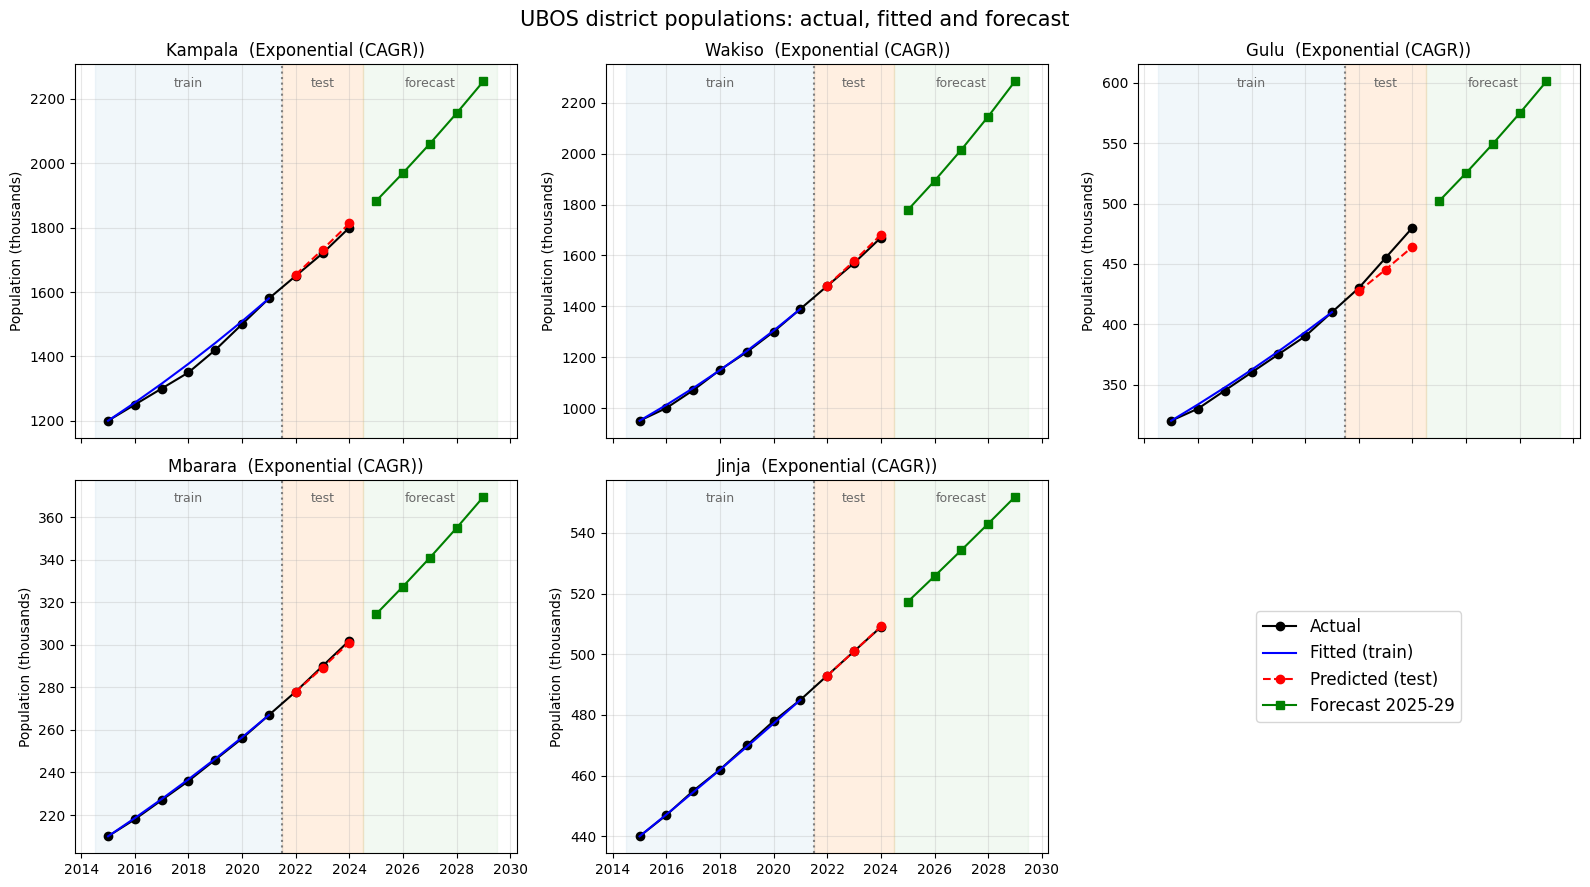

In [18]:
def plot_districts(intervals=None):
    """Draw one subplot per district.

    Parameters
    ----------
    intervals : dict or None
        Optional {district: (lower, upper)} arrays to shade a 95% band
        around the forecast.
    """
    fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True)
    axes = axes.ravel()                           # flatten 2x3 grid into a simple list

    for ax, (name, d) in zip(axes, districts.items()):
        is_train = d.years <= LAST_TRAIN_YEAR
        is_test = ~is_train

        # Model trained ONLY on the training years (for fitted + test predictions)
        ModelClass = MODELS[best_model[name]]
        train_model = ModelClass().fit(d.years[is_train], d.populations[is_train])

        # Coloured background zones
        ax.axvspan(2014.5, LAST_TRAIN_YEAR + 0.5, color="tab:blue", alpha=0.06)
        ax.axvspan(LAST_TRAIN_YEAR + 0.5, 2024.5, color="tab:orange", alpha=0.12)
        ax.axvspan(2024.5, 2029.5, color="tab:green", alpha=0.06)
        ax.axvline(LAST_TRAIN_YEAR + 0.5, color="grey", linestyle=":")   # the train/test split line

        # The four lines
        ax.plot(d.years, d.populations, "ko-", label="Actual")
        ax.plot(d.years[is_train], train_model.fitted(), "b-", label="Fitted (train)")
        ax.plot(d.years[is_test], train_model.predict(int(is_test.sum())), "r--o",
                label="Predicted (test)")
        ax.plot(FORECAST_YEARS, forecasts[name], "g-s", label="Forecast 2025-29")

        # Optional 95% prediction interval
        if intervals is not None:
            lower, upper = intervals[name]
            ax.fill_between(FORECAST_YEARS, lower, upper, color="tab:green", alpha=0.25,
                            label="95% interval")

        # Zone labels at the top of each subplot
        for x, text in [(2018, "train"), (2023, "test"), (2027, "forecast")]:
            ax.text(x, 0.94, text, transform=ax.get_xaxis_transform(),
                    ha="center", fontsize=9, color="dimgrey")

        ax.set_title(f"{name}  ({best_model[name]})")
        ax.set_ylabel("Population (thousands)")
        ax.grid(alpha=0.3)

    # The 6th panel is unused, so use it to hold the legend
    handles, labels = axes[0].get_legend_handles_labels()
    axes[-1].axis("off")
    axes[-1].legend(handles, labels, loc="center", fontsize=12)

    fig.suptitle("UBOS district populations: actual, fitted and forecast", fontsize=15)
    plt.tight_layout()
    plt.show()


plot_districts()

## 8. Planning output: extra classrooms needed by 2029

**Assumptions (from the brief):**
- 18% of the population is of primary-school age.
- One classroom holds 53 pupils.
- Our data is in **thousands**, so multiply by 1,000 to get people.
- "Additional" classrooms = classrooms needed in 2029 **minus** classrooms needed in 2024 (we assume today's classrooms exactly match 2024 need, because we have no other data about existing classrooms).
- We **round up** (`np.ceil`) because you cannot build 0.4 of a classroom.

In [19]:
# PRIMARY_SHARE, PUPILS_PER_CLASSROOM and classrooms_needed() come from src/analysis.py

plan_rows = {}
for name, d in districts.items():
    rooms_2024 = classrooms_needed(d.populations[-1])        # based on the actual 2024 population
    rooms_2029 = classrooms_needed(forecasts[name][-1])      # last forecast value = 2029
    plan_rows[name] = {
        "Pop 2024 (k)":      d.populations[-1],
        "Pop 2029 (k)":      forecasts[name][-1],
        "Classrooms 2024":   rooms_2024,
        "Classrooms 2029":   rooms_2029,
        "ADDITIONAL needed": rooms_2029 - rooms_2024,
    }

# orient="index" keeps each column's own type (decimals vs whole classrooms)
plan_table = pd.DataFrame.from_dict(plan_rows, orient="index")
display(plan_table)
print("Total additional classrooms across the 5 districts:", int(plan_table["ADDITIONAL needed"].sum()))

,Pop 2024 (k),Pop 2029 (k),Classrooms 2024,Classrooms 2029,ADDITIONAL needed
Kampala,"1,800.00","2,254.76",6114,7658,1544
Wakiso,"1,670.00","2,284.67",5672,7760,2088
Gulu,480.00,601.27,1631,2043,412
Mbarara,302.00,369.54,1026,1256,230
Jinja,509.00,551.91,1729,1875,146


Total additional classrooms across the 5 districts: 4420


---
# Extension

## Extension A: Bootstrap 95% prediction intervals

A forecast is one line, but the future is uncertain. A **bootstrap** estimates that uncertainty using only our own data:

1. Fit the model to the real data and compute the **residuals** (actual - fitted): the leftover wiggles the model could not explain.
2. Build a *fake* history: fitted values + residuals **randomly re-drawn (with replacement)**.
3. Re-fit the model on the fake history and forecast 5 years. Add one random residual to each forecast year (the future will wiggle too).
4. Repeat **1,000 times**. The 2.5th and 97.5th percentiles of the 1,000 forecasts form a **95% prediction interval**.

In [20]:
# bootstrap_interval() is defined in src/forecasting.py

intervals = {}
for name, d in districts.items():
    intervals[name] = bootstrap_interval(MODELS[best_model[name]], d.years, d.populations,
                                         HORIZON, n_boot=1000)

# Show 2029 as an example of the interval width
interval_2029 = pd.DataFrame({
    name: {"Lower 2.5%": intervals[name][0][-1],
           "Forecast":   forecasts[name][-1],
           "Upper 97.5%": intervals[name][1][-1]}
    for name in districts
}).T
print("2029 forecast with 95% interval (thousands):")
display(interval_2029)

2029 forecast with 95% interval (thousands):


,Lower 2.5%,Forecast,Upper 97.5%
Kampala,"2,198.94","2,254.76","2,287.40"
Wakiso,"2,254.92","2,284.67","2,311.84"
Gulu,575.09,601.27,607.96
Mbarara,367.02,369.54,370.18
Jinja,551.33,551.91,553.92


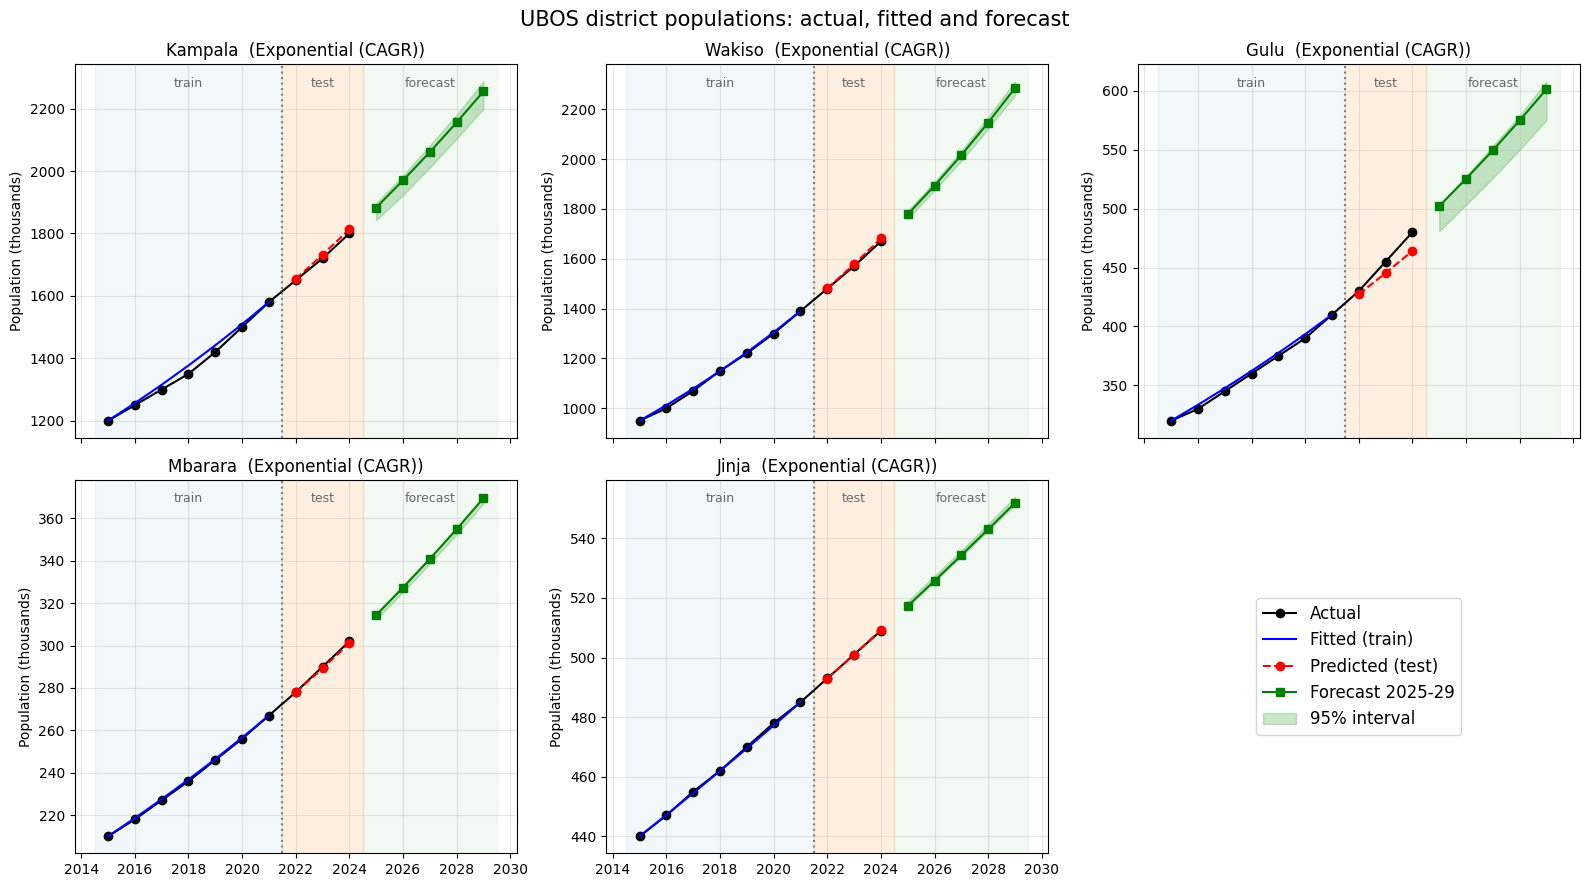

In [21]:
plot_districts(intervals=intervals)     # same plot, now with the shaded green bands

**Reading the bands:** they widen the further ahead we look, because each year's uncertainty builds on the last. They are fairly narrow because the exponential model follows the history closely, so the residuals are tiny. Be careful: the bands only capture *noise seen in the past*. They cannot capture a regime change (a new road, a policy, a pandemic), so real uncertainty is larger than the bands suggest.

## Extension B: Is the Fibonacci-ratio model defensible?

What the model really assumes: multiplying by 1.5, 1.67, 1.6, 1.625, ... means the population grows by **about 60% every single year**, and the ratios settle at the golden ratio 1.618. Let's compare that with reality.

In [22]:
fib_growth = (fibonacci_ratios(HORIZON) - 1) * 100
print("Growth per year implied by the Fibonacci model (%):", np.round(fib_growth, 1))
print("Highest observed CAGR in our data (%):             ", round(summary["CAGR (%)"].max(), 2))

fib_check = {}
for name, d in districts.items():
    fib_2029 = FibonacciRatioForecaster().fit(d.years, d.populations).predict(HORIZON)[-1]
    fib_check[name] = {"Selected model 2029 (k)": forecasts[name][-1],
                       "Fibonacci model 2029 (k)": fib_2029,
                       "Fibonacci is x times larger": fib_2029 / forecasts[name][-1]}
display(pd.DataFrame(fib_check).T)

Growth per year implied by the Fibonacci model (%): [50.  66.7 60.  62.5 61.5]
Highest observed CAGR in our data (%):              6.47


,Selected model 2029 (k),Fibonacci model 2029 (k),Fibonacci is x times larger
Kampala,"2,254.76","18,900.00",8.38
Wakiso,"2,284.67","17,535.00",7.68
Gulu,601.27,"5,040.00",8.38
Mbarara,369.54,"3,171.00",8.58
Jinja,551.91,"5,344.50",9.68


### Assessment

**Why it fails here.** Our districts grow roughly 2-6% per year, but the model assumes about 60%. In five years it multiplies the population by about 10 (1.5 x 1.67 x 1.6 x 1.625 x 1.615 = 10.5), so Kampala would go from 1.8 million to about 19 million, against about 2.3 million from the selected model (see the table above). The validation table already warned us (MAPE above 100%).

**Other weaknesses**
- **No link to the data:** it ignores the history, using only the last value. Linear and exponential models learn their growth rate from the data.
- **No limits:** real populations face capacity (land, services, migration). The model grows without any ceiling.
- **Numerology, not mechanism:** Fibonacci numbers come from the rule F(n) = F(n-1) + F(n-2), an idealised rabbit-breeding story. Human populations do not follow that rule.

**When could it be defensible?** Only if all of these hold:
1. The quantity really is growing by about 60% per period (about 1.618x), for example early-stage user growth of an app, a bacteria colony in ideal conditions or an epidemic's first weeks.
2. The horizon is short (a few periods), before limits kick in.
3. It is checked against back-testing, like in section 5.

**A fix worth trying:** use the *inverse* ratios (0.618, 0.5, ...) to **damp** growth instead of multiplying by it, or apply Fibonacci ratios to the *yearly increment* rather than to the level. That would give slowing growth, which is more realistic. But it needs the same back-test evidence before it is trusted.

## Summary

| Question | Answer |
|---|---|
| Fastest growing (relative) | see the CAGR table in section 3 |
| Best model per district | see the best-model table in section 5 |
| Forecast 2025-2029 | forecast table in section 6 |
| Extra classrooms by 2029 | plan table in section 8 |
| Biggest lesson | Validate on held-out data; a forecast without an uncertainty band is only half an answer |

## Findings & Limitations

**Findings.** Wakiso is the fastest-growing district in relative terms (CAGR 6.5% a year), while Kampala and Gulu tie at 4.6%. So "fastest" depends on whether we count people added or percentage growth. In back-testing, the exponential model beat the linear and Fibonacci models in all five districts (for Kampala, RMSE about 10 thousand against 39 thousand for the linear trend). This suggests growth is compounding: the yearly percentage is steady, so the yearly increase keeps rising. The Fibonacci model implies about 60% growth a year and forecasts 8 to 10 times more people than the selected models, so it is unusable for population. For planning, the five districts need about 4,420 additional classrooms by 2029. Wakiso and Kampala together account for over 80% of them, so they should be prioritised.

**Limitations.** The data is illustrative, and Mbarara and Jinja are invented, so the numbers demonstrate the method, not real conditions. Validation used only three test years, so the choice of model is weakly supported. The exponential model grows without limit, whereas real growth may slow with migration, falling fertility or land constraints. The bootstrap bands are narrow because the past residuals are tiny; they ignore policy shocks and understate real uncertainty. The classroom estimates assume 18% of people are of primary-school age, 53 pupils per class, and that 2024 classrooms exactly match 2024 need. Replacing the data with UBOS census figures should come before any real decision.